<a href="https://colab.research.google.com/github/100522155/egci463/blob/main/Reading_digit_with_SKlearn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# 1. Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB, GaussianNB
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [3]:
# 2. Data Loading
# For Colab:

import io
from google.colab import files
uploaded = files.upload()
df = pd.read_csv(io.BytesIO(uploaded["digit.csv"]), header=None)

# If running locally, use:
#df = pd.read_csv("digit.csv", header=None)


Saving digit.csv to digit.csv


In [4]:
 #3. Quick Data Inspection
print("Shape:", df.shape)
print("First few rows:\n", df.head())

Shape: (500, 785)
First few rows:
    0    1    2    3    4    5    6    7    8    9    ...  775  776  777  778  \
0    0    0    0    0    0    0    0    0    0    0  ...    0    0    0    0   
1    0    0    0    0    0    0    0    0    0    0  ...    0    0    0    0   
2    0    0    0    0    0    0    0    0    0    0  ...    0    0    0    0   
3    0    0    0    0    0    0    0    0    0    0  ...    0    0    0    0   
4    0    0    0    0    0    0    0    0    0    0  ...    0    0    0    0   

   779  780  781  782  783  784  
0    0    0    0    0    0    0  
1    0    0    0    0    0    0  
2    0    0    0    0    0    0  
3    0    0    0    0    0    0  
4    0    0    0    0    0    0  

[5 rows x 785 columns]


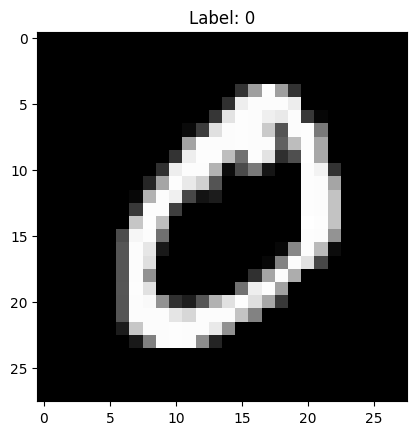

In [5]:
# 4. Visualize a Sample Digit
first_digit = np.array(df.iloc[0, :-1]).reshape(28, 28)
plt.imshow(first_digit, cmap="gray")
plt.title(f"Label: {df.iloc[0, -1]}")
plt.show()


In [6]:
# 5. Reshape for Further Analysis (optional)
# For access as [digit][sample][features] if needed
digit_images = np.array(df.iloc[:, :-1]).reshape(-1, 28, 28)

In [7]:
# 6. Binarize Images (thresholding)
bin_digits = (df.iloc[:, :-1] > 128).astype(int)


In [8]:
# 7. Prepare Data dataframe --> values
X = bin_digits.values
y = df.iloc[:, -1].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)



In [9]:
# 8. Train Multinomial Naive Bayes Model
model_mn = MultinomialNB().fit(X_train, y_train)


In [10]:
# 9. Show Test prediction and compare with the actual value
y_pred=model_mn.predict(X_test)
print("Prediction and Actual value" )
np.array([y_pred ,y_test]).T

Prediction and Actual value


array([[7, 7],
       [1, 1],
       [7, 7],
       [3, 3],
       [2, 2],
       [7, 7],
       [7, 7],
       [2, 2],
       [1, 1],
       [9, 9],
       [0, 0],
       [0, 3],
       [8, 8],
       [1, 1],
       [9, 7],
       [7, 7],
       [9, 9],
       [0, 0],
       [6, 6],
       [8, 8],
       [9, 9],
       [9, 9],
       [5, 5],
       [7, 7],
       [1, 1],
       [9, 9],
       [9, 9],
       [4, 4],
       [2, 2],
       [6, 6],
       [9, 9],
       [6, 6],
       [8, 8],
       [3, 3],
       [8, 0],
       [6, 6],
       [1, 8],
       [1, 1],
       [4, 4],
       [1, 1],
       [9, 7],
       [1, 1],
       [9, 9],
       [3, 3],
       [0, 0],
       [1, 1],
       [0, 0],
       [0, 0],
       [8, 8],
       [0, 0],
       [1, 1],
       [3, 3],
       [2, 2],
       [8, 8],
       [3, 3],
       [5, 1],
       [1, 2],
       [0, 0],
       [5, 4],
       [1, 1],
       [9, 9],
       [5, 5],
       [6, 6],
       [9, 9],
       [1, 1],
       [0, 0],
       [9,

In [11]:
# 10. Compare the probability
np.set_printoptions(precision=5,suppress=True)
y_prob = model_mn.predict_proba(X_test)
print(y_prob)

[[0.      0.      0.      0.      0.      0.      0.      1.      0.
  0.     ]
 [0.      1.      0.      0.      0.      0.      0.      0.      0.
  0.     ]
 [0.      0.      0.      0.      0.      0.      0.      1.      0.
  0.     ]
 [0.      0.      0.      0.99997 0.      0.00003 0.      0.      0.
  0.     ]
 [0.      0.01049 0.9814  0.00812 0.      0.      0.      0.      0.
  0.     ]
 [0.      0.      0.      0.      0.      0.      0.      1.      0.
  0.     ]
 [0.      0.      0.      0.      0.      0.      0.      1.      0.
  0.     ]
 [0.      0.      1.      0.      0.      0.      0.      0.      0.
  0.     ]
 [0.      0.99999 0.      0.      0.      0.      0.      0.      0.00001
  0.     ]
 [0.      0.      0.      0.      0.      0.      0.      0.      0.
  1.     ]
 [1.      0.      0.      0.      0.      0.      0.      0.      0.
  0.     ]
 [0.46223 0.      0.41017 0.00408 0.      0.12352 0.      0.      0.
  0.     ]
 [0.      0.      0.      0.      0

In [12]:
# Show the result with probability
np.set_printoptions(threshold=np.inf, linewidth=np.inf)
Result=np.hstack((y_prob, y_pred.reshape(-1, 1)))
print(Result)

[[0.      0.      0.      0.      0.      0.      0.      1.      0.      0.      7.     ]
 [0.      1.      0.      0.      0.      0.      0.      0.      0.      0.      1.     ]
 [0.      0.      0.      0.      0.      0.      0.      1.      0.      0.      7.     ]
 [0.      0.      0.      0.99997 0.      0.00003 0.      0.      0.      0.      3.     ]
 [0.      0.01049 0.9814  0.00812 0.      0.      0.      0.      0.      0.      2.     ]
 [0.      0.      0.      0.      0.      0.      0.      1.      0.      0.      7.     ]
 [0.      0.      0.      0.      0.      0.      0.      1.      0.      0.      7.     ]
 [0.      0.      1.      0.      0.      0.      0.      0.      0.      0.      2.     ]
 [0.      0.99999 0.      0.      0.      0.      0.      0.      0.00001 0.      1.     ]
 [0.      0.      0.      0.      0.      0.      0.      0.      0.      1.      9.     ]
 [1.      0.      0.      0.      0.      0.      0.      0.      0.      0.      0.     ]

In [13]:
# 11. Count the mislabeled
print("Number of mislabeled points out of a total %d points " , (y_test != y_pred).sum())

print("The accuracy is %.2f"%((y_test == y_pred).mean()*100) +"%" )


Number of mislabeled points out of a total %d points  12
The accuracy is 88.00%


In [14]:
# 12. Use score to find the accuracy
print("MultinomialNB train accuracy:", model_mn.score(X_train, y_train))
print("MultinomialNB test accuracy:", model_mn.score(X_test, y_test))

MultinomialNB train accuracy: 0.86
MultinomialNB test accuracy: 0.88


In [15]:
# 13. Some parameters

print(model_mn.classes_)
print(model_mn.class_count_)
#print(model_mn.class_prior_) NOT AVAILABLE IN MULTINOMIAL
print(model_mn.feature_count_)
print(model_mn.feature_log_prob_)

[0 1 2 3 4 5 6 7 8 9]
[39. 33. 45. 41. 46. 44. 38. 38. 41. 35.]
[[ 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  1.  1.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  3.  9.  9. 10. 13. 13.  9.  3.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  1.  3.  3. 10. 15. 23. 28. 30. 29. 27. 20. 15.  9.  2.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  1.  4.  6. 13. 14. 23. 27. 32. 36. 35. 30. 31. 20. 15.  8.  1.  1.  1.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  3.  6.  9. 12. 22. 26. 34. 32. 32. 33. 34. 32. 28. 21. 12.  4.  3.  1.  0.  0.  0.  0.  0.  0.  0.  0.  0.  2.  5.  9. 11

Referece: https://scikit-learn.org/stable/modules/naive_bayes.html


In [16]:
# 14. Create a confusion Matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm = confusion_matrix(y_test, y_pred, labels=model_mn.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model_mn.classes_)

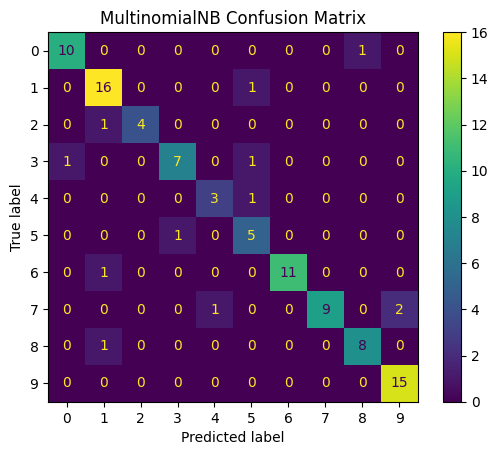

In [17]:
disp.plot()
plt.title("MultinomialNB Confusion Matrix")
plt.show()

Reference:https://scikit-learn.org/stable/auto_examples/model_selection/plot_confusion_matrix.html


# Gaussian Navie Bayes

In [18]:
# 1. Train Gaussian Naive Bayes Model
model_gb = GaussianNB().fit(X_train, y_train)
y_pred2 =model_gb.predict(X_test)
np.array([y_pred2, y_test]).T


array([[9, 7],
       [1, 1],
       [9, 7],
       [3, 3],
       [2, 2],
       [7, 7],
       [9, 7],
       [2, 2],
       [8, 1],
       [9, 9],
       [0, 0],
       [0, 3],
       [8, 8],
       [1, 1],
       [9, 7],
       [7, 7],
       [9, 9],
       [0, 0],
       [6, 6],
       [8, 8],
       [4, 9],
       [9, 9],
       [5, 5],
       [7, 7],
       [1, 1],
       [9, 9],
       [4, 9],
       [4, 4],
       [2, 2],
       [6, 6],
       [9, 9],
       [6, 6],
       [8, 8],
       [3, 3],
       [8, 0],
       [6, 6],
       [1, 8],
       [1, 1],
       [4, 4],
       [1, 1],
       [7, 7],
       [1, 1],
       [8, 9],
       [2, 3],
       [0, 0],
       [8, 1],
       [0, 0],
       [0, 0],
       [8, 8],
       [0, 0],
       [1, 1],
       [2, 3],
       [2, 2],
       [8, 8],
       [3, 3],
       [5, 1],
       [1, 2],
       [0, 0],
       [4, 4],
       [8, 1],
       [8, 9],
       [5, 5],
       [6, 6],
       [9, 9],
       [1, 1],
       [0, 0],
       [9,

In [19]:
# 2. Show output parameters

np.set_printoptions(precision=5,suppress=True)
y_prob = model_gb.predict_proba(X_test)
print(y_prob)
result = np.hstack((y_prob, y_test.reshape(-1, 1)))
print(result)

[[0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
 [0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
 [0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
 [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 1. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
 [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]
 [0. 0. 0.

In [20]:
#3 Task 1. Compare the prediction output and the real test data
print("Accuracy: ",((y_test == y_pred2).mean() *100) , "%")

Accuracy:  76.0 %


In [21]:
#3 Task 2. Compare and find mislabelled data
mislabeled = (y_test != y_pred2).sum()
total = len(y_test)
print("Bad clasiffied:", mislabeled, "of",total)

Bad clasiffied: 24 of 100


In [22]:
#4 Task 3. Compute the score of both train/test
train_score = model_gb.score(X_train, y_train)
test_score  = model_gb.score(X_test, y_test)

print("Train Accuracy Score:" , train_score)
print("Test Accuracy Score:  ",test_score)

Train Accuracy Score: 0.855
Test Accuracy Score:   0.76


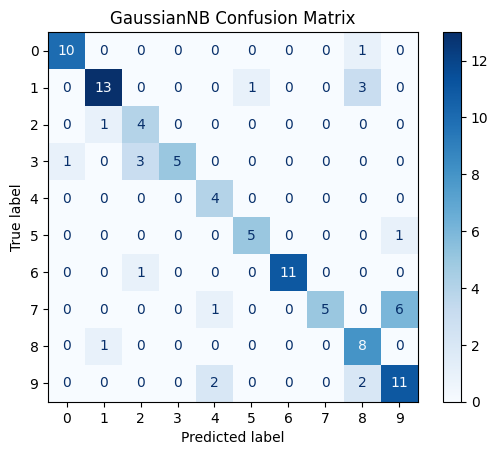

In [23]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cmd = confusion_matrix(y_test, y_pred2, labels=model_mn.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cmd, display_labels=model_mn.classes_)
disp.plot(cmap ="Blues")
plt.title("GaussianNB Confusion Matrix")
plt.show()

In [24]:
# Use score to find the accuracy
print("Bayes train accuracy:", model_gb.score(X_train, y_train))
print("Bayes test accuracy:", model_gb.score(X_test, y_test))

Bayes train accuracy: 0.855
Bayes test accuracy: 0.76


In [25]:
#5 Task 4. Computer Precision of all data (How it can be done? Explain the result)
tp = np.diag(cmd) #Obtains the elements of the diagonal
pred_per_column = cmd.sum(axis=0)
print("Extracted elements from the diagonal \n",tp)
print()
print("Predicted clases \n",pred_per_column) #Added elements of the vertical
print()
precision = tp / pred_per_column
print("Real hits / Total predictions per class \n",precision) #Real hits / Total predictions per class


Extracted elements from the diagonal 
 [10 13  4  5  4  5 11  5  8 11]

Predicted clases 
 [11 15  8  5  7  6 11  5 14 18]

Real hits / Total predictions per class 
 [0.90909 0.86667 0.5     1.      0.57143 0.83333 1.      1.      0.57143 0.61111]


In [26]:
#6 Task 5. Computer Recall  of all data How it can be done? Explain the result)
# Add horizontally per rows (axis=1) -> Real data per class (TP + FN)
actual_per_row = cmd.sum(axis=1)
recall = tp / actual_per_row #Calculate recall per class
average_recall = recall.mean()
print("True positives (TP):\n", tp)
print("\n Total of real data per class (Rows):\n", actual_per_row)
print("\nRecall per class:\n", recall)
print("\nAverage Recall of all data:", average_recall * 100 ,"%")


True positives (TP):
 [10 13  4  5  4  5 11  5  8 11]

 Total of real data per class (Rows):
 [11 17  5  9  4  6 12 12  9 15]

Recall per class:
 [0.90909 0.76471 0.8     0.55556 1.      0.83333 0.91667 0.41667 0.88889 0.73333]

Average Recall of all data: 78.18241235888294 %


### Explanation of Precision and Recall

Precision (per class) = TP / (TP + FP): of all images the model labelled as digit *k*, how many really were *k*.
Recall (per class) = TP / (TP + FN): of all real images of digit *k*, how many the model found.
With 10 classes, each digit is treated as the "positive" class once (one-vs-rest). All values are computed on the test set (100 images) from the GaussianNB confusion matrix. The average recall printed above (78.2 %) is the unweighted mean over the 10 classes. Weighting each class by its number of samples (average='weighted') gives a precision of 0.818 and a recall of 0.760; the weighted recall is equal to the test accuracy (0.76).
Digit 2 has the lowest precision (0.50): the model predicts "2" 8 times but only 4 are correct, mainly because 3 real 3s (and one real 6) are labelled 2 (many FP). Digits 4 and 8 follow with 0.571.
Digit 7 has the lowest recall (0.417): only 5 of the 12 real 7s are found and 6 are labelled 9 (many FN). Digit 3 is next (0.556): 3 of its 9 images are labelled 2. Digit 4 has perfect recall (1.0) but low precision, because some 7s and 9s are labelled 4.

### Comparison with the previous exercise (MultinomialNB)

| Model | Train acc. | Test acc. | Mislabeled (test, of 100) |
|---|---|---|---|
| MultinomialNB | 0.86 | 0.88 | 12 |
| GaussianNB | 0.855 | 0.76 | 24 |

Observations
GaussianNB reached a test accuracy of 0.76 compared with 0.88 for MultinomialNB, so MultinomialNB performs better (12 more correct predictions out of 100, half the errors).
Both models have almost the same train accuracy (~0.86), but GaussianNB drops about 9.5 points on the test set (0.855 → 0.76), while MultinomialNB does not drop (0.86 → 0.88). GaussianNB therefore generalizes worse (overfitting).
Most confused digits with GaussianNB: 7→9 (6 times), 3→2 (3 times), 1→8 (3 times), 9→4 and 9→8 (2 times each). With MultinomialNB the errors are fewer and more spread out: 7→9 (2 times) and several single errors.
GaussianNB assumes that each pixel follows a normal distribution per class. In this dataset 206 of the 784 pixels are always 0 (borders), and after binarization the other pixels only take the values 0 or 1, so they are not bell-shaped. The estimated variances are very small or unreliable, which makes the likelihoods extreme and the model overconfident. MultinomialNB treats the pixel value like a count, which fits this kind of data better and is more stable.

In [27]:
uploaded2 = files.upload()
df2 = pd.read_csv(io.BytesIO(uploaded2["Weight_Height_M_W.csv"]))

Saving Weight_Height_M_W.csv to Weight_Height_M_W.csv


In [28]:
#Separate each data per etiquete and train_test_split
X2 = df2[["Height", "Weight"]].values
y2 = df2["gender"].values
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y2, test_size=0.2, random_state=42)


In [29]:
priors = [0.35, 0.65]                       # in order of np.unique(y2): [M, W]
model_gender = GaussianNB(priors=priors).fit(X2_train, y2_train)
y2_pred = model_gender.predict(X2_test)

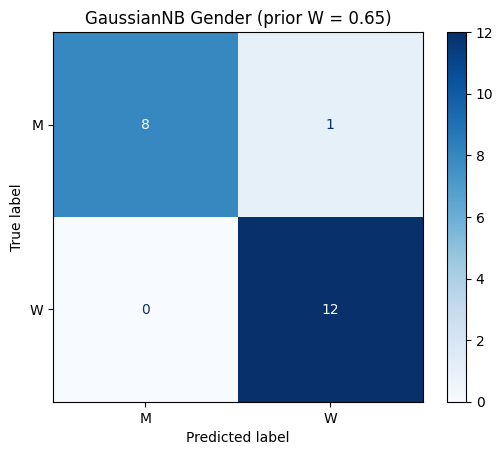

In [30]:
cm2 = confusion_matrix(y2_test, y2_pred, labels=model_gender.classes_)
disp2 = ConfusionMatrixDisplay(cm2, display_labels=model_gender.classes_)
disp2.plot(cmap="Blues")
plt.title("GaussianNB Gender (prior W = 0.65)")
plt.show()

Without custom priors (estimated from the data: M = 0.5625, W = 0.4375) the result is identical: accuracy 0.95 and the same confusion matrix [[8, 1], [0, 12]]. The prior of 0.65 does not change the predictions here because the test samples are well separated by height and weight; only borderline cases would be affected.

# Assignment 4

Continue from the previous lab (Classify with Bayesian)
(Don't forget to train test split)

→TASK1
use PCA to reduce to lower dimension +use Bayes’s approach (at least .95 )

In [31]:
from sklearn import preprocessing
# Create the standard scaler
scaler = preprocessing.StandardScaler() #Standardscaler is a prepocessing tool
# Standarize =   transform each píxel to mean 0 & deviation 1: x’ = (x − μ) / σ.
#Learns mean and deviation from train data & transforms (does also scaler.fit(X_train) to fit on TRAIN data only)
X_train_std = scaler.fit_transform(X_train) #Apply transformation to train data
X_test_std  = scaler.transform(X_test) #Apply transformation to test data

In [32]:
from sklearn.decomposition import PCA
pca = PCA(n_components=0.95)
#Orders the numbers regarding how much importance they have in the variance
#Keeps the minimun number of components to conserve the 95% of the variance
X_train_pca = pca.fit_transform(X_train_std)
X_test_pca  = pca.transform(X_test_std) #Learns in train and transforms train and test

In [33]:
model_pca = GaussianNB().fit(X_train_pca, y_train)
#Trains a model with the reduced data
#Calculates the proportion of hits
print("Train accuracy:", model_pca.score(X_train_pca, y_train))
print("Test accuracy :", model_pca.score(X_test_pca, y_test))

Train accuracy: 0.8925
Test accuracy : 0.76


→TASK2
Plot the first 2 Components to 2 D plot of at least 2-3 digits

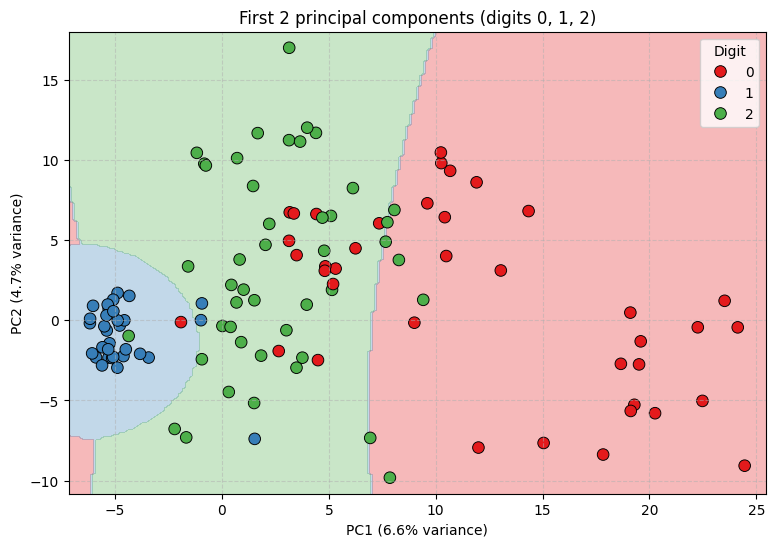

Variance explained by PC1 + PC2: 0.1128995391492208


In [44]:
import seaborn as sns

#Conserves the two highest variance directions
pca_2d = PCA(n_components=2)
X_train_pca2d = pca_2d.fit_transform(X_train_std)   # learn only with train

# Choose 3 digits that is wanted to draw
selected_digits = [0, 1, 2]
mask = np.isin(y_train, selected_digits)
#To see which images are from the selected_digits

X_plot = X_train_pca2d[mask] # Images from selected digits from x_train
y_plot = y_train[mask] #Images from selected digits from y_train

plt.figure(figsize=(9, 6))

#Create the regions in the graphic
x_min, x_max = X_plot[:, 0].min() - 1, X_plot[:, 0].max() + 1
y_min, y_max = X_plot[:, 1].min() - 1, X_plot[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))

g = GaussianNB()
g.fit(X_plot, y_plot)
Z = g.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

#Parameters to adjust
var = pca_2d.explained_variance_ratio_
cols = sns.color_palette("Set1", 3)
plt.contourf(xx, yy, Z, alpha=0.3, levels=[-0.5, 0.5, 1.5, 2.5], colors=cols)
#Draw graphic
sns.scatterplot(x=X_plot[:, 0], y=X_plot[:, 1], hue=y_plot,
                palette=cols, hue_order=[0, 1, 2], s=70, edgecolor="k")
plt.xlabel(f"PC1 ({var[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({var[1]*100:.1f}% variance)")
plt.title("First 2 principal components (digits 0, 1, 2)")
plt.legend(title="Digit", loc="best")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

print("Variance explained by PC1 + PC2:", var.sum())

→Task3
Plot Discrimination region (consult week 1 Assingment)

→Compare the result from the full dimension (How much reduction has it made)

Accuracy 2D (train): 0.7863247863247863


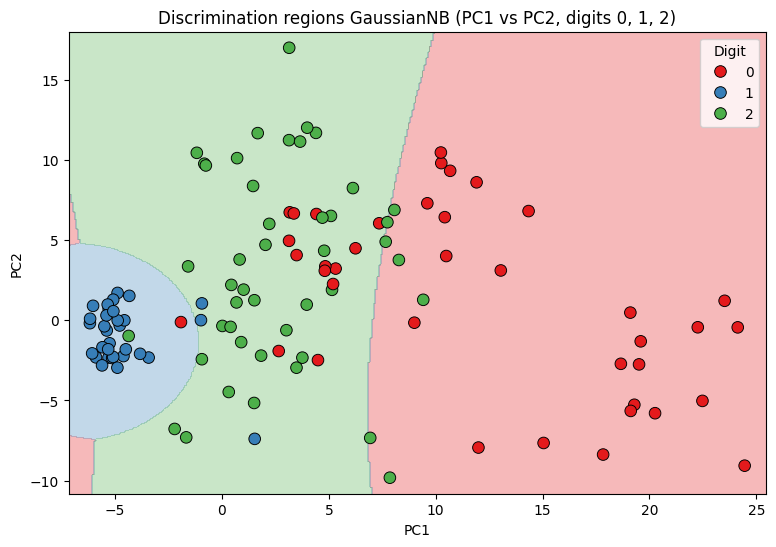

In [35]:

import numpy as np
import matplotlib.pyplot as plt

model_2d = GaussianNB().fit(X_plot, y_plot)
print("Accuracy 2D (train):", model_2d.score(X_plot, y_plot))

x_min, x_max = X_plot[:, 0].min() - 1, X_plot[:, 0].max() + 1
y_min, y_max = X_plot[:, 1].min() - 1, X_plot[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 400),
                     np.linspace(y_min, y_max, 400))

Z = model_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(9, 6))
cols = sns.color_palette("Set1", 3)
plt.contourf(xx, yy, Z, alpha=0.3, levels=[-0.5, 0.5, 1.5, 2.5], colors=cols)
sns.scatterplot(x=X_plot[:, 0], y=X_plot[:, 1], hue=y_plot,
                palette=cols, hue_order=[0, 1, 2], s=70, edgecolor="k")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("Discrimination regions GaussianNB (PC1 vs PC2, digits 0, 1, 2)")
plt.legend(title="Digit")
plt.show()



Extra, with 10 digits, more chaotic

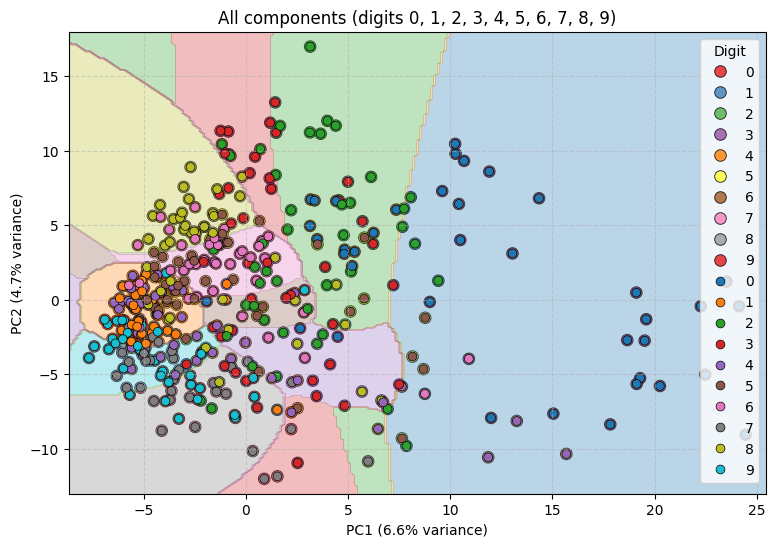

Variance explained by PC1 + PC2: 0.11289954161315319


In [36]:
import seaborn as sns

#Conserves the two highest variance directions
pca_2d = PCA(n_components=2)
X_train_pca2d = pca_2d.fit_transform(X_train_std)   # learn only with train

# Choose 3 digits that is wanted to draw
selected_digits = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
mask = np.isin(y_train, selected_digits)
#To see which images are from the selected_digits

X_plot = X_train_pca2d[mask] # Images from selected digits from x_train
y_plot = y_train[mask] #Images from selected digits from y_train

plt.figure(figsize=(9, 6))
#Draw graphic
sns.scatterplot( x=X_plot[:, 0], y=X_plot[:, 1], hue=y_plot,
    palette="Set1", s=70, alpha=0.8, edgecolor="k")

#Create the regions in the graphic
x_min, x_max = X_plot[:, 0].min() - 1, X_plot[:, 0].max() + 1
y_min, y_max = X_plot[:, 1].min() - 1, X_plot[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))

g = GaussianNB()
g.fit(X_plot, y_plot)
Z = g.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

#Parameters to adjust
var = pca_2d.explained_variance_ratio_
cols = sns.color_palette("tab10", 10)
plt.contourf(xx, yy, Z, alpha=0.3, levels=np.arange(-0.5, 10.5, 1), colors=cols)
sns.scatterplot(x=X_plot[:, 0], y=X_plot[:, 1], hue=y_plot,
                palette=cols, hue_order=list(range(10)), s=40, edgecolor="k")
plt.xlabel(f"PC1 ({var[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({var[1]*100:.1f}% variance)")
plt.title("All components (digits 0, 1, 2, 3, 4, 5, 6, 7, 8, 9)")
plt.legend(title="Digit", loc="best")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

print("Variance explained by PC1 + PC2:", var.sum())

Comparation

In [37]:
import time

t0 = time.time()
m_full = GaussianNB().fit(X_train, y_train)
t_full = time.time() - t0

t1 = time.time()
m_95= GaussianNB().fit(X_train_pca, y_train)
t_95 = time.time() - t1

d_full = X_train.shape[1]
d_95   = pca.n_components_

print(f"Times: \n full: { t_full:.5f} \n PCA:  {t_95:.5f}")

print("Complete dimension :", d_full)
print("Dimensions with PCA   :", d_95)
print(f"Reduction             : {(1 - d_95/d_full)*100:.1f}%")

m_full = GaussianNB().fit(X_train, y_train)
print("Test accuracy complete:", m_full.score(X_test, y_test))
print("Test accuracy PCA 95% :", model_pca.score(X_test_pca, y_test))


Times: 
 full: 0.02922 
 PCA:  0.00648
Complete dimension : 784
Dimensions with PCA   : 185
Reduction             : 76.4%
Test accuracy complete: 0.76
Test accuracy PCA 95% : 0.76


With PCA (95 % of the variance) the data goes from 784 to 185 dimensions (76.4 % reduction) and the test accuracy stays the same (0.76 vs 0.76), while the training time drops (0.0038 s vs 0.0087 s). The 0.95 refers to the variance kept by PCA. The first two components explain only 11.3 % of the variance, so in the 2D plots the classes overlap: the plot is only for visualization, not for classification.